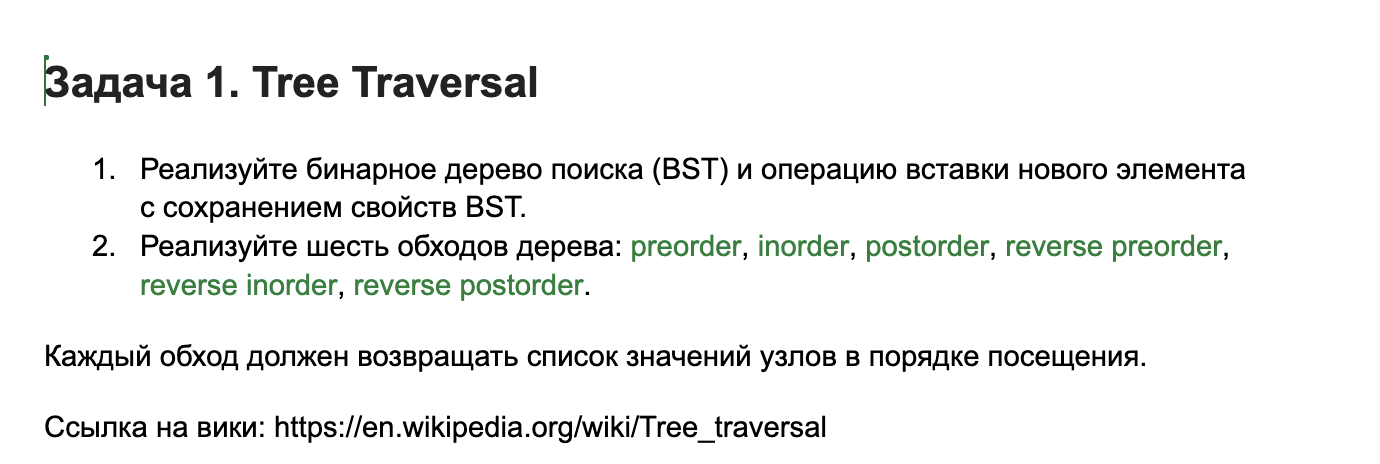

## Ход решения

Начнем с того, как устроено **BST (бинарное дерево поиска)**. У  каждой её вершины значения в левом поддереве **строго меньше**, а в правом - **больше или равны** её значению. Поэтому при вставке мы сравниваем новое число с текущей вершиной и каждый раз выбираем только одну ветку.

Также необходимо в дереве еще реализовать вставку. Ее очевидно реализуем рекурсивно (подробнее ниже).

 Шесть обходов дерева тоже сделаем рекурсивно через **DFS** (поиск в глубину). У них одна идея: обойти оба поддерева и записать значение текущей вершины. Отличается только порядок этих трёх действий. Подробнее также ниже показано все.


### Вставка элемента

Сначала создаём класс `Node`: в каждой вершине хранятся значение `value` и ссылки на левого (`left`) и правого (`right`) ребёнка.

В классе `BST` есть `self.root` — корень дерева. Изначально это `None`, потому что дерево пустое.

Как работает `insert(node, value)`:

1. **Проверяем текущую вершину.** Если `node is None`, мы дошли до свободного места. Создаём `Node(value)` и возвращаем её.
2. **Если `value < node.value`, идём влево.** Нужно идти влево, потому что мы можем найти значения, которые еще меньше - после которых мы и хотим вставить элемент, затем вызываем `self.insert(node.left, value)` и записываем результат в `node.left`.
3. **Иначе идём вправо.** Сюда попадают и большие, и **равные** значения: вызываем `self.insert(node.right, value)` и записываем результат в `node.right`. Обычно, конечно, не просят дубликаты учиывать, но я решил это добавить на всякий слуай.
4. **Возвращаем `node`.** Пока рекурсивные вызовы заканчиваются, каждый родитель снова получает ссылку на своё поддерево. Так новая вершина остаётся связанной с остальными. Иначе после того, как мы создали вершину новую, мы бы никакие вместе не соединили.

Например, если у вершины `5` уже есть правый ребёнок `7` и мы вставляем ещё одну `5`, то сначала пойдём вправо к `7`, а затем влево от `7` и создадим новую `5`. **Равенство означает выбор правой ветки при сравнении, но не обязательно создание непосредственного правого ребёнка.**

Чтобы сохранить корень после вставки, вызываем `tree.root = tree.insert(tree.root, value)`.


### Обходы дерева

Для всех функций договоримся:

- `N` — текущая вершина (`node`), `L` — левое поддерево (`node.left`), `R` — правое (`node.right`).
- `result` — общий список, куда мы записываем значения. При первом вызове он создаётся пустым, а при рекурсивных вызовах передаётся дальше **тот же список**.
- Если `node is None`, функция заканчивается: вершины нет, добавлять нечего.
- `result.append(node.value)` записывает текущую вершину. Вызов `preorder(node.left, result)` (и аналогичные вызовы) обходит целое поддерево, прежде чем управление вернётся назад.

| Обход | Порядок |
| --- | --- |
| `preorder` | `N → L → R` |
| `inorder` | `L → N → R` |
| `postorder` | `L → R → N` |
| `reverse_preorder` | `N → R → L` |
| `reverse_inorder` | `R → N → L` |
| `reverse_postorder` | `R → L → N` |

#### 1. Preorder — сначала вершина, затем левое и правое поддеревья

1. Приходим в `node` и **сразу записываем** `node.value` в `result`.
2. Рекурсивно обходим **всё левое поддерево**.
3. Когда закончили слева, рекурсивно обходим **всё правое поддерево**.

Поэтому корень любого поддерева попадает в список **раньше** своих потомков.

#### 2. Inorder — левое поддерево, вершина, правое поддерево

1. Сначала рекурсивно уходим **влево**. Если там есть следующие левые дети, продолжаем спускаться.
2. Когда слева больше некуда идти, **записываем текущую вершину**.
3. Затем рекурсивно обходим **правое поддерево**.

Для BST значения получаются **по неубыванию**: от меньших к большим, включая повторы.

#### 3. Postorder — левое поддерево, правое поддерево, вершина

1. Сначала полностью обходим **левое поддерево**.
2. Затем полностью обходим **правое поддерево**.
3. **Только после обоих поддеревьев** записываем значение текущей вершины.

Поэтому корень любого поддерева попадает в список **после** своих потомков. Корень всего дерева будет последним.

#### 4. Reverse preorder — вершина, правое поддерево, левое поддерево

1. Сразу **записываем текущую вершину**.
2. Полностью обходим **правое поддерево**.
3. После него обходим **левое поддерево**.

Это зеркальный `preorder`: корень по-прежнему первый, но сначала идём направо.

#### 5. Reverse inorder — правое поддерево, вершина, левое поддерево

1. Сначала рекурсивно спускаемся **вправо**.
2. После завершения правого поддерева **записываем текущую вершину**.
3. Затем обходим **левое поддерево**.

Для BST значения получаются **по невозрастанию**: от больших к меньшим, включая повторы.

#### 6. Reverse postorder — правое поддерево, левое поддерево, вершина

1. Полностью обходим **правое поддерево**.
2. Полностью обходим **левое поддерево**.
3. **В самом конце** записываем текущую вершину.

Это зеркальный `postorder`: корень остаётся последним, но сначала обрабатывается правая сторона.


## Сложность алгоритма

Пусть `n` — количество вершин в дереве, а `h` — его высота.

| Операция | Время | Дополнительная память |
| --- | ---: | ---: |
| Вставка в BST | `O(h)` | `O(h)` |
| Любой из шести обходов | `O(n)` | `O(n + h)` |

**Вставка.** На каждом шаге идём только в одну ветку, поэтому число рекурсивных вызовов зависит от высоты дерева `h`. В сбалансированном дереве `h = O(log n)`, а в дереве-цепочке `h = O(n)`. В частности, цепочка возникает, если последовательно вставлять одинаковые значения: все они уходят вправо. Дополнительная память `O(h)` нужна для стека рекурсии; ещё `O(1)` занимает новая вершина.

**Обходы.** Каждую вершину посещаем ровно один раз, поэтому время `O(n)`. Список `result` хранит все `n` значений и занимает `O(n)`, а рекурсивные вызовы — `O(h)`. Если не считать возвращаемый список, дополнительная память составляет `O(h)`.


# Реализация

Сначала реализуем обычную вершину дерева. У неё есть значение и ссылки на левого и правого ребёнка.

In [1]:
class Node:
    def __init__(self, value):
        self.value = value
        self.left = None
        self.right = None

### BST и вставка элемента

In [2]:
class BST:
    def __init__(self):
        self.root = None

    def insert(self, node, value):
        if node is None:
            return Node(value)

        if value < node.value:
            node.left = self.insert(node.left, value)
        else:
            node.right = self.insert(node.right, value)

        return node

### Шесть обходов DFS

Каждый обход — отдельная функция. Чтобы не усложнять рекурсию, оставим их в простом виде, без `self` и вспомогательных методов.

In [3]:
def preorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    result.append(node.value)
    preorder(node.left, result)
    preorder(node.right, result)

    return result


def inorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    inorder(node.left, result)
    result.append(node.value)
    inorder(node.right, result)

    return result


def postorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    postorder(node.left, result)
    postorder(node.right, result)
    result.append(node.value)

    return result


def reverse_preorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    result.append(node.value)
    reverse_preorder(node.right, result)
    reverse_preorder(node.left, result)

    return result


def reverse_inorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    reverse_inorder(node.right, result)
    result.append(node.value)
    reverse_inorder(node.left, result)

    return result


def reverse_postorder(node, result=None):
    if result is None:
        result = []

    if node is None:
        return result

    reverse_postorder(node.right, result)
    reverse_postorder(node.left, result)
    result.append(node.value)

    return result

# Визуализация работы алгоритма

Возьмём нетривиальный пример: сначала построим дерево с разными значениями, а затем **дважды вставим значения, которые уже встречались**.

```python
values = [8, 3, 10, 1, 6, 14, 4, 7, 13, 6, 8]
```

### 1. Пошаговая вставка

На каждом шаге начинаем с корня, сравниваем число с текущей вершиной и выбираем сторону. Знак `=` тоже ведёт вправо.

| Шаг | Значение | Как находим место для вставки |
| ---: | ---: | --- |
| 1 | `8` | Пустое дерево → создаём корень `8` |
| 2 | `3` | `3 < 8` → слева от `8` |
| 3 | `10` | `10 > 8` → справа от `8` |
| 4 | `1` | `1 < 8`, `1 < 3` → слева от `3` |
| 5 | `6` | `6 < 8`, `6 > 3` → справа от `3` |
| 6 | `14` | `14 > 8`, `14 > 10` → справа от `10` |
| 7 | `4` | `4 < 8`, `4 > 3`, `4 < 6` → слева от `6` |
| 8 | `7` | `7 < 8`, `7 > 3`, `7 > 6` → справа от `6` |
| 9 | `13` | `13 > 8`, `13 > 10`, `13 < 14` → слева от `14` |
| 10 | `6` (повтор) | `6 < 8`, `6 > 3`, `6 = 6` → идём **вправо** к `7`, затем `6 < 7` → слева от `7` |
| 11 | `8` (повтор) | `8 = 8` → идём **вправо** к `10`, затем `8 < 10` → слева от `10` |

Итоговое дерево (`6` и `8` встречаются по два раза):

```text
          8
        /   \
       3     10
      / \   /  \
     1   6 8    14
        / \     /
       4   7    13
          /
         6
```

Обрати внимание: дополнительная `6` находится **слева от `7`**, но мы попали туда, сперва пойдя **вправо от уже существующей `6`**. Поэтому правило «при равенстве идём вправо» соблюдается.

### 2. Пошаговые обходы на этом дереве

#### Preorder (`N → L → R`)

1. Записываем корень `8`.
2. Идём влево от него: записываем `3`, затем `1`; возвращаемся и обходим поддерево `6`: сначала `6`, затем `4`, затем `7` и его левую `6`.
3. Идём вправо от корня: записываем `10`, его левую `8`, затем `14` и `13`.

**Порядок:** `8 → 3 → 1 → 6 → 4 → 7 → 6 → 10 → 8 → 14 → 13`.

#### Inorder (`L → N → R`)

1. Уходим как можно левее: встречаем `1`, записываем её и возвращаемся к `3`, которую тоже записываем.
2. Идём в правое поддерево `3`: записываем `4`, затем `6`, затем вторую `6` и `7`.
3. Теперь записываем корень `8`.
4. Справа обходим поддерево `10`: сначала повторную `8`, потом `10`, затем `13` и `14`.

**Порядок:** `1 → 3 → 4 → 6 → 6 → 7 → 8 → 8 → 10 → 13 → 14`.

#### Postorder (`L → R → N`)

1. Сначала завершаем левое поддерево корня: `1`, `4`, повторную `6`, `7`, первую `6`, затем `3`.
2. После этого завершаем правое: повторную `8`, `13`, `14`, затем `10`.
3. Только в конце записываем корень `8`.

**Порядок:** `1 → 4 → 6 → 7 → 6 → 3 → 8 → 13 → 14 → 10 → 8`.

#### Reverse preorder (`N → R → L`)

1. Сразу записываем корень `8`.
2. Сначала идём вправо: `10`, `14`, `13`, затем повторная `8` слева от `10`.
3. Потом идём влево от корня: `3`, `6`, `7`, повторная `6`, `4`, `1`.

**Порядок:** `8 → 10 → 14 → 13 → 8 → 3 → 6 → 7 → 6 → 4 → 1`.

#### Reverse inorder (`R → N → L`)

1. Начинаем с самой правой части: записываем `14`, `13`, возвращаемся к `10`, затем записываем повторную `8`.
2. Записываем корень `8`.
3. Обходим левую часть справа налево: `7`, повторную `6`, первую `6`, `4`, `3`, `1`.

**Порядок:** `14 → 13 → 10 → 8 → 8 → 7 → 6 → 6 → 4 → 3 → 1`.

#### Reverse postorder (`R → L → N`)

1. В правом поддереве обходим сначала правую часть: `13`, `14`, затем левую `8` и только после этого `10`.
2. В левом поддереве обходим сначала правую часть: повторную `6`, `7`, `4`, первую `6`; потом `1` и в конце `3`.
3. Последним записываем корень `8`.

**Порядок:** `13 → 14 → 8 → 10 → 6 → 7 → 4 → 6 → 1 → 3 → 8`.

Итого все обходы прошли через **каждую из 11 вершин** ровно по одному разу, включая два значения `6` и два значения `8`. Они различаются только порядком добавления в `result`.

### 3. Сравнение результатов

| Обход | Результат |
| --- | --- |
| `preorder` | `[8, 3, 1, 6, 4, 7, 6, 10, 8, 14, 13]` |
| `inorder` | `[1, 3, 4, 6, 6, 7, 8, 8, 10, 13, 14]` |
| `postorder` | `[1, 4, 6, 7, 6, 3, 8, 13, 14, 10, 8]` |
| `reverse_preorder` | `[8, 10, 14, 13, 8, 3, 6, 7, 6, 4, 1]` |
| `reverse_inorder` | `[14, 13, 10, 8, 8, 7, 6, 6, 4, 3, 1]` |
| `reverse_postorder` | `[13, 14, 8, 10, 6, 7, 4, 6, 1, 3, 8]` |


# Тесты

Проверим вставку и все шесть обходов на разных случаях:

- пустое дерево и дерево из одной вершины;
- нетривиальное дерево из визуализации со смешанными левыми и правыми ветками;
- возрастающие и убывающие последовательности (дерево превращается в цепочку);
- отрицательные значения и ноль;
- повторяющиеся значения, включая несколько одинаковых подряд — **дубликаты должны сохраняться**, а при равенстве вставляться вправо;
- результат каждого обхода содержит столько значений, сколько было вставлено, а повторный обход даёт тот же результат.


Сначала добавим небольшую функцию, которая по списку значений строит BST с помощью нашей `insert`.

In [4]:
def build_tree(values):
    tree = BST()

    for value in values:
        tree.root = tree.insert(tree.root, value)

    return tree

### Проверка точного порядка всех шести обходов, включая повторяющиеся значения


In [5]:
values = [8, 3, 10, 1, 6, 14, 4, 7, 13, 6, 8]
tree = build_tree(values)

traversals = {
    "preorder": preorder,
    "inorder": inorder,
    "postorder": postorder,
    "reverse_preorder": reverse_preorder,
    "reverse_inorder": reverse_inorder,
    "reverse_postorder": reverse_postorder,
}

expected_orders = {
    "preorder": [8, 3, 1, 6, 4, 7, 6, 10, 8, 14, 13],
    "inorder": [1, 3, 4, 6, 6, 7, 8, 8, 10, 13, 14],
    "postorder": [1, 4, 6, 7, 6, 3, 8, 13, 14, 10, 8],
    "reverse_preorder": [8, 10, 14, 13, 8, 3, 6, 7, 6, 4, 1],
    "reverse_inorder": [14, 13, 10, 8, 8, 7, 6, 6, 4, 3, 1],
    "reverse_postorder": [13, 14, 8, 10, 6, 7, 4, 6, 1, 3, 8],
}

for name, traversal in traversals.items():
    assert traversal(tree.root) == expected_orders[name], name

print("Все 6 обходов на нетривиальном дереве работают корректно")

Все 6 обходов на нетривиальном дереве работают корректно


### Основные, граничные и дополнительные случаи

In [6]:
test_cases = [
    ([], []),
    ([5], [5]),
    ([1, 2, 3, 4], [1, 2, 3, 4]),
    ([4, 3, 2, 1], [1, 2, 3, 4]),
    ([-5, -1, -3, 0, 2], [-5, -3, -1, 0, 2]),
    ([5, 5, 3, 7, 3, 7], [3, 3, 5, 5, 7, 7]),
    ([5, 5, 5, 5], [5, 5, 5, 5]),
    ([0, -10, 10, -5, 5, 5, 10], [-10, -5, 0, 5, 5, 10, 10]),
    ([8, 3, 10, 1, 6, 14, 4, 7, 13, 6, 8], [1, 3, 4, 6, 6, 7, 8, 8, 10, 13, 14]),
    ([6, 2, 9, 1, 4, 8, 11, 3, 5], [1, 2, 3, 4, 5, 6, 8, 9, 11]),
]

for values, expected in test_cases:
    tree = build_tree(values)

    assert inorder(tree.root) == expected
    assert reverse_inorder(tree.root) == expected[::-1]

    for traversal in traversals.values():
        result = traversal(tree.root)
        assert isinstance(result, list)
        assert len(result) == len(values)
        assert sorted(result) == expected
        assert traversal(tree.root) == result

print("Основные, граничные и дополнительные тесты пройдены")

Основные, граничные и дополнительные тесты пройдены


### Проверка того, что одинаковые значения вставляются в правое поддерево


In [7]:
tree = build_tree([5, 3, 7])
root = tree.root
left = root.left
right = root.right

tree.root = tree.insert(tree.root, 3)
tree.root = tree.insert(tree.root, 5)
tree.root = tree.insert(tree.root, 7)

assert tree.root is root
assert tree.root.left is left
assert tree.root.right is right
assert tree.root.left.right.value == 3
assert tree.root.right.left.value == 5
assert tree.root.right.right.value == 7
assert inorder(tree.root) == [3, 3, 5, 5, 7, 7]

tree = build_tree([5, 5, 5])
assert tree.root.right.value == 5
assert tree.root.right.right.value == 5
assert inorder(tree.root) == [5, 5, 5]

print("Повторяющиеся значения сохраняются и вставляются вправо")

Повторяющиеся значения сохраняются и вставляются вправо
